In [17]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/customers_clean.csv", parse_dates=["InvoiceDate"])

cutoff = pd.Timestamp("2011-09-09")
horizon_end = cutoff + pd.Timedelta(days=90)

past = df[df["InvoiceDate"] < cutoff]
future = df[(df["InvoiceDate"] >= cutoff) & (df["InvoiceDate"] < horizon_end)]
print(past["InvoiceDate"].max(), future["InvoiceDate"].min(), future["InvoiceDate"].max())

2011-09-08 19:58:00 2011-09-09 08:48:00 2011-12-07 17:25:00


In [18]:
g = past.groupby("Customer ID")
feat = g.agg(
    Recency=("InvoiceDate", lambda x: (cutoff - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
    Products=("StockCode", "nunique"),
    First=("InvoiceDate", "min"),
)
feat["Tenure"] = (cutoff - feat["First"]).dt.days
feat["AvgOrderValue"] = feat["Monetary"] / feat["Frequency"]
feat = feat.drop(columns="First")

# Only customers who were still active in the 180 days before the cutoff
feat = feat[feat["Recency"] <= 180]
print(feat.shape)

(2775, 6)


In [19]:
inv = (past.drop_duplicates(["Customer ID", "Invoice"])
           [["Customer ID", "Invoice", "InvoiceDate"]]
           .sort_values(["Customer ID", "InvoiceDate"]))

# average days between orders
gap = inv.groupby("Customer ID")["InvoiceDate"].apply(lambda s: s.diff().dt.days.mean())
feat["AvgGapDays"] = gap.reindex(feat.index).fillna(gap.median())

# how overdue the customer is compared with their normal rhythm
feat["OverdueRatio"] = feat["Recency"] / (feat["AvgGapDays"] + 1)

# recent activity
for d in (30, 90):
    recent = inv[inv["InvoiceDate"] >= cutoff - pd.Timedelta(days=d)]
    feat[f"Orders_last{d}d"] = recent.groupby("Customer ID")["Invoice"].nunique().reindex(feat.index).fillna(0)

# share of activity that is recent
feat["RecentShare90"] = feat["Orders_last90d"] / feat["Frequency"]
print(feat.shape)

(2775, 11)


In [20]:
bought_again = set(future["Customer ID"].unique())
feat["Churn"] = (~feat.index.isin(bought_again)).astype(int)
print(feat["Churn"].value_counts())
print("Churn rate:", round(feat["Churn"].mean() * 100, 1), "%")

Churn
0    1707
1    1068
Name: count, dtype: int64
Churn rate: 38.5 %


In [21]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

X = feat.drop(columns="Churn")
y = feat["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, eval_metric="auc", random_state=42,
)
model.fit(X_train, y_train)

proba = model.predict_proba(X_test)[:, 1]
print("Features:", X.columns.tolist())
print("AUC-ROC:", round(roc_auc_score(y_test, proba), 3))

Features: ['Recency', 'Frequency', 'Monetary', 'Products', 'Tenure', 'AvgOrderValue', 'AvgGapDays', 'OverdueRatio', 'Orders_last30d', 'Orders_last90d', 'RecentShare90']
AUC-ROC: 0.699


In [22]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
print("CV AUC:", cv_auc.round(3), "mean:", cv_auc.mean().round(3))

CV AUC: [0.785 0.755 0.748 0.777 0.781] mean: 0.769


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(X_train, y_train)
print("Logistic regression AUC:", round(roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]), 3))
print("Recency-only AUC:", round(roc_auc_score(y_test, X_test["Recency"]), 3))

Logistic regression AUC: 0.706
Recency-only AUC: 0.616


In [24]:
k = int(len(y_test) * 0.2)
top_idx = np.argsort(proba)[::-1][:k]
print("Precision@top20%:", round(y_test.values[top_idx].mean(), 3))
print("Baseline churn rate in test set:", round(y_test.mean(), 3))

Precision@top20%: 0.604
Baseline churn rate in test set: 0.386


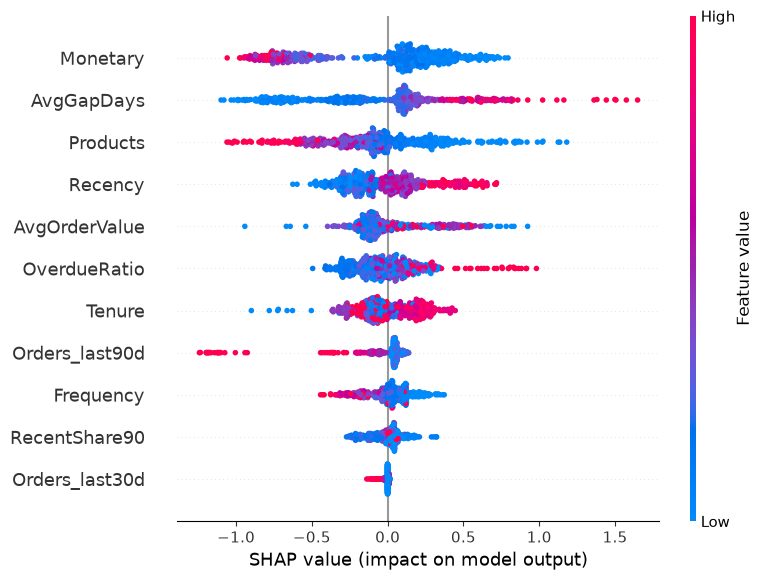

In [25]:
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, show=False)
plt.savefig("../reports/figures/15_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
scores = X.copy()
scores["ChurnProb"] = model.predict_proba(X)[:, 1]
scores = scores.reset_index()
scores.to_csv("../data/processed/churn_scores.csv", index=False)
print("Saved", scores.shape)

Saved (2775, 13)
